## Laboratorio 1/6 con Pytorch
Nombre: Espinoza Chiri Soledad Griselda Carrera: Ing de Sistemas

**Construya un programa en python que permita encontrar los mejores valores de b y w de la ecuación de la línea recta: y = b + wx, a partir de un dataset que usted seleccione, no se debe utilizar ningún framework o ecuaciones de regresiones, solo debe realizar un programa simple, con estructuras de control decisivo y repetitivo. Una vez que identifique los mejores valores de b y w, realice inferencias para 10 nuevos valores de x, explique los resultados obtenidos y el algoritmo empleado.**

# Dataset Seleccionado
Student Study Hours dataset.<br>
Este dataset representa la relación entre las horas que un estudiante dedica a estudiar y la calificación (score) que obtiene.
Donde x = Hours, variable independiente (lo que ya conocemos).<br>
y = Scores, variable dependiente (lo que queremos predecir a partir de x).

In [1]:
# Conectando / vinculando nuestro drive con la sesión de Google Colab
from google.colab import drive
drive.mount('/content/drive')

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# Semilla para reproducibilidad
torch.manual_seed(0)

Mounted at /content/drive


# Cargar Dataset

In [2]:
# Cargar el dataset desde Google Drive
ruta = '/content/drive/MyDrive/SIS420/student_scores.csv'

with open(ruta, 'r') as f:
    contenido = f.readlines()

print("Total de registros (incluye encabezado):", len(contenido))
print("Encabezado:", contenido[0].strip())
print("Vista previa:")
for fila in contenido[1:6]:
    print(fila.strip())

Total de registros (incluye encabezado): 36
Encabezado: Hours,Scores
Vista previa:
2.5,21
5.1,47
3.2,27
8.5,75
3.5,30


In [3]:
horas = []
notas = []

indice = 0
for fila in contenido:
    if indice == 0:
        indice += 1
        continue
    fila = fila.strip()
    if fila == "":
        continue
    valores = fila.split(",")
    horas.append(float(valores[0]))
    notas.append(float(valores[1]))
    indice += 1

n = len(horas)
print("Cantidad de estudiantes:", n)
print("Horas (primeros 5):", horas[:5])
print("Notas (primeros 5):", notas[:5])

Cantidad de estudiantes: 35
Horas (primeros 5): [2.5, 5.1, 3.2, 8.5, 3.5]
Notas (primeros 5): [21.0, 47.0, 27.0, 75.0, 30.0]


# Objeto Dataset
Definimos una clase que hereda de `torch.utils.data.Dataset`, tal como se muestra en el cuadernillo `03_pytorch_datasets`, para encapsular el manejo de los datos (horas de estudio y calificaciones).

In [4]:
# Clase Dataset, hereda de la clase `torch.utils.data.Dataset`
class DatasetHorasEstudio(torch.utils.data.Dataset):

    def __init__(self, x, y):

        self.x = torch.tensor(x, dtype=torch.float32).view(-1, 1)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, ix):
        return self.x[ix], self.y[ix]

dataset = DatasetHorasEstudio(horas, notas)
print("Cantidad de ejemplos en el dataset:", len(dataset))
print("Primer ejemplo (x, y):", dataset[0])

Cantidad de ejemplos en el dataset: 35
Primer ejemplo (x, y): (tensor([2.5000]), tensor([21.]))


# Objeto DataLoader
El `DataLoader` recibe el `Dataset` e implementa la lógica para iterar los datos en *batches*, mezclándolos en cada época con `shuffle=True`.

In [5]:
dataloader = torch.utils.data.DataLoader(dataset, batch_size=8, shuffle=True)

x_batch, y_batch = next(iter(dataloader))
print("Forma del batch de x:", x_batch.shape)
print("Forma del batch de y:", y_batch.shape)

Forma del batch de x: torch.Size([8, 1])
Forma del batch de y: torch.Size([8, 1])


# Definición del modelo
Definimos el modelo de regresión lineal como una clase personalizada que hereda de `torch.nn.Module`, con una única capa `nn.Linear(1, 1)`. Los parámetros de esta capa (`weight` y `bias`) corresponden exactamente a `w` y `b` de la ecuación y = b + wx del Laboratorio 1.

In [6]:
class RegresionLineal(nn.Module):

    def __init__(self):
        super(RegresionLineal, self).__init__()
        self.fc = nn.Linear(1, 1)

    def forward(self, x):
        return self.fc(x)

model = RegresionLineal()
model

RegresionLineal(
  (fc): Linear(in_features=1, out_features=1, bias=True)
)

# Objetos para optimización y costo
En lugar de calcular a mano el error cuadrático medio y actualizar `b` y `w` manualmente, utilizamos los objetos que nos ofrece `PyTorch`: `nn.MSELoss` como función de costo y `torch.optim.SGD` (descenso de gradiente estocástico).

In [7]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Entrenamiento del modelo

In [8]:
num_epochs = 200
historial_costo = []

model.train()
for epoch in range(num_epochs):
    costo_epoch = 0.0
    for x_batch, y_batch in dataloader:

        outputs = model(x_batch)
        loss = criterion(outputs, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        costo_epoch += loss.item() * x_batch.size(0)

    costo_epoch /= len(dataset)
    historial_costo.append(costo_epoch)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {costo_epoch:.4f}')

Epoch [20/200], Loss: 36.3837
Epoch [40/200], Loss: 36.2387
Epoch [60/200], Loss: 34.8733
Epoch [80/200], Loss: 42.9382
Epoch [100/200], Loss: 38.7447
Epoch [120/200], Loss: 39.0309
Epoch [140/200], Loss: 36.2194
Epoch [160/200], Loss: 40.9300
Epoch [180/200], Loss: 35.6045
Epoch [200/200], Loss: 40.2088


# Pesos aprendidos (b y w)

In [9]:
w = model.fc.weight.item()
b = model.fc.bias.item()

print(f"Mejor w (pendiente):  {round(w, 4)}")
print(f"Mejor b (intercepto): {round(b, 4)}")
print(f"Costo final:          {round(historial_costo[-1], 4)}")

Mejor w (pendiente):  9.8047
Mejor b (intercepto): 3.2088
Costo final:          40.2088


# Guardando los pesos del modelo
Guardamos únicamente el `state_dict` del modelo (sus pesos), y luego lo volvemos a cargar para comprobar que funciona correctamente.

In [10]:
PATH = '/content/drive/MyDrive/SIS420/lab1_checkpoint.pt'
torch.save(model.state_dict(), PATH)
print("Pesos guardados en:", PATH)

# Cargamos el modelo desde los pesos guardados
modelo_cargado = RegresionLineal()
modelo_cargado.load_state_dict(torch.load(PATH))
modelo_cargado.eval()

Pesos guardados en: /content/drive/MyDrive/SIS420/lab1_checkpoint.pt


RegresionLineal(
  (fc): Linear(in_features=1, out_features=1, bias=True)
)

# Inferencia con 10 nuevos valores de x

In [11]:
horas_nuevas = [0.5, 1.8, 2.7, 3.9, 4.6, 5.8, 6.4, 7.5, 8.9, 9.5]
x_nuevas = torch.tensor(horas_nuevas, dtype=torch.float32).view(-1, 1)

print("Predicciones de calificación según horas de estudio:\n")
with torch.no_grad():
    predicciones = modelo_cargado(x_nuevas)
    for h, pred in zip(horas_nuevas, predicciones):
        nota_estimada = min(pred.item(), 100.0)
        print(f'Horas de estudio = {h:4.1f} -> calificación estimada = {nota_estimada:.2f}')

Predicciones de calificación según horas de estudio:

Horas de estudio =  0.5 -> calificación estimada = 8.11
Horas de estudio =  1.8 -> calificación estimada = 20.86
Horas de estudio =  2.7 -> calificación estimada = 29.68
Horas de estudio =  3.9 -> calificación estimada = 41.45
Horas de estudio =  4.6 -> calificación estimada = 48.31
Horas de estudio =  5.8 -> calificación estimada = 60.08
Horas de estudio =  6.4 -> calificación estimada = 65.96
Horas de estudio =  7.5 -> calificación estimada = 76.74
Horas de estudio =  8.9 -> calificación estimada = 90.47
Horas de estudio =  9.5 -> calificación estimada = 96.35


# Generación de métricas


In [12]:
model.eval()
with torch.no_grad():
    y_pred = model(dataset.x)

y_real = dataset.y.numpy()
y_pred_np = y_pred.numpy()

mse = mean_squared_error(y_real, y_pred_np)
rmse = np.sqrt(mse)
r2 = r2_score(y_real, y_pred_np)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")

MSE:  34.6581
RMSE: 5.8871
R2:   0.9349


# Gráficas de resultados

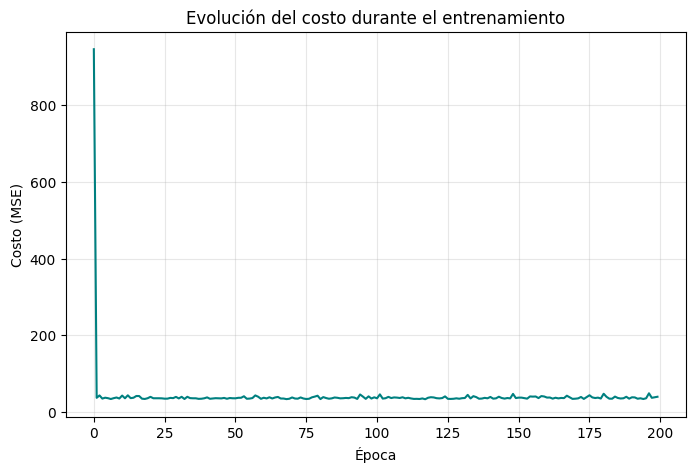

In [13]:

plt.figure(figsize=(8,5))
plt.plot(historial_costo, color='teal')
plt.xlabel('Época')
plt.ylabel('Costo (MSE)')
plt.title('Evolución del costo durante el entrenamiento')
plt.grid(True, alpha=0.3)
plt.show()

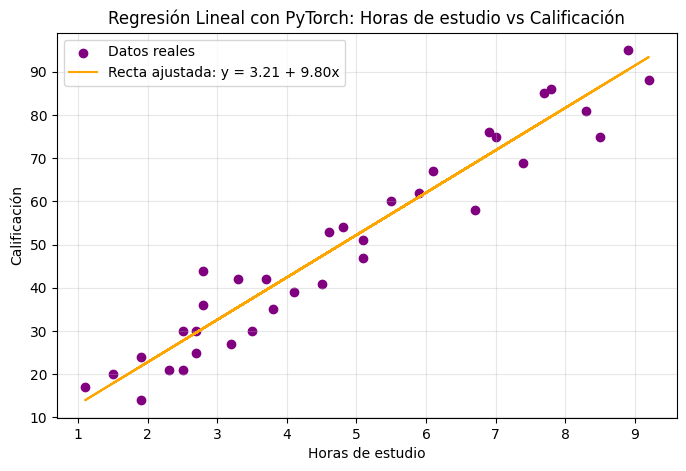

In [14]:

with torch.no_grad():
    notas_predichas = model(dataset.x).numpy().flatten()

plt.figure(figsize=(8,5))
plt.scatter(horas, notas, color='purple', label='Datos reales')
plt.plot(horas, notas_predichas, color='orange', label=f'Recta ajustada: y = {b:.2f} + {w:.2f}x')
plt.xlabel('Horas de estudio')
plt.ylabel('Calificación')
plt.title('Regresión Lineal con PyTorch: Horas de estudio vs Calificación')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()